# V4A Failure Atlas and TRAIN exposure audit

## tl;dr

The fixed A4096 cohort contains **16 independently audited DEV conditions: 8 successes and 8 valid failures**. B is still queued in this snapshot: **there is no B−A estimate**. This is one original noise panel, not full DEV or confirmation.

Both retained training branches consumed **131,072 actual anchors** after the shared CORR2048 initializer. B consumed 49,152 new-bank anchors; A consumed none. Original T2 detach-stage Prefix8 supervision reached all 30 parents in both arms. In the new T1 bank, the physical grasp-end-after-transport event entered sampled Prefix8 windows for 67/75 parents, while H40 supervision reached all 75. This does not prove missing task-release supervision or a learning deficit.

The 24 future task conditions below reuse 12 already frozen TRAIN geometries. They are metadata-only candidates, with no new capture, optimizer update or runtime registration.

## Context & Methods

This companion audits saved evidence and the retained training lineage. It does not change scoring, R0, the sampler, safety gates, WBC, the active server owner, or scientific scope.

### Key Assumptions

- A training visit is one observation anchor with H40 target supervision, not an independent demonstration. Prefix8 means target positions 0–7, spanning 0–0.35 s; H40 spans 0–1.95 s.
- Old T2 detach/withdraw names are **Teacher-stage annotations**. New-bank grasp/contact/zone events are separately defined **physical transitions**. Neither becomes a policy input or a new TRAIN label here.
- The native audit checks all retained cursors, saved sampler digests and forward-microbatch identities. Paid failed/discarded updates remain in the financial history but are not relabelled as retained endpoint ancestry.
- Event-first times describe observed milestones, not causal neural failure mechanisms. Grasp end is not complete task release. Missing B outcomes are unknown, not failures or zero success.
- This notebook uses original shared scoring utilities for a read-side equality check; it is not a new independent native audit.

## Data

Committed JSON/CSV artifacts beside this notebook are the public reviewed analysis inputs. Original arrays, worker traces and host-bound receipts remain private. Set `PV1_AUDIT_EVIDENCE_DIR` and `PV1_ADMITTED_EVENTS_PATH` to the existing authorized local evidence if rerunning the optional byte-level checks; no connector, SSH, token, model or physics call is made by this notebook.

In [1]:
from pathlib import Path
import os, json, hashlib, csv, io, base64, itertools, sys
import numpy as np
from IPython.display import display, HTML

ROOT = Path.cwd()
if not (ROOT / 'reports/PI0294').is_dir():
    ROOT = next(p for p in [ROOT, *ROOT.parents] if (p / 'reports/PI0294').is_dir())
REPORT_DIR = ROOT / 'reports/PI0294/design/parallel-science-20261022'
PREFIX = 'V4A_FAILURE_ATLAS_AND_TRAIN_AUDIT_20261025'
load = lambda name: json.loads((REPORT_DIR / (PREFIX + '_' + name + '.json')).read_bytes())
atlas, training, candidates = load('FAILURE_ATLAS'), load('TRAIN_COVERAGE'), load('TEACHER_CANDIDATES')
sha = lambda raw: hashlib.sha256(raw).hexdigest()
def table(rows):
    import html
    keys = list(rows[0])
    header = ''.join('<th>' + html.escape(str(k)) + '</th>' for k in keys)
    body = ''.join('<tr>' + ''.join('<td>' + html.escape(str(r[k])) + '</td>' for k in keys) + '</tr>' for r in rows)
    display(HTML('<table><thead><tr>' + header + '</tr></thead><tbody>' + body + '</tbody></table>'))
assert len(atlas['actual_condition_timelines']) == 16
assert atlas['comparison']['paired_conditions'] == 0 and atlas['comparison']['effect_estimates'] is None
assert sum(r['status'] == 'SUCCESS' for r in atlas['actual_condition_timelines']) == 8
print('Reviewed cohort: 16 A conditions; B outcomes unavailable; no treatment-effect estimate.')

Reviewed cohort: 16 A conditions; B outcomes unavailable; no treatment-effect estimate.


### Actual exposure and grain checks

The rows below are forward-consumed anchors joined to the checkpoint-retained cursor ranges. They replace neither the old expected-exposure draft nor any financial history.

In [2]:
lane_rows = []
for arm, lanes in training['actual_by_candidate_lane'].items():
    assert sum(r['actual_sample_visits'] for r in lanes.values()) == 131072
    for lane, row in lanes.items():
        lane_rows.append({'Arm': arm, 'Lane': lane, 'Consumed anchors': row['actual_sample_visits'],
                          'Episode IDs': row['distinct_episode_ids'], 'Episode/anchor pairs': row['distinct_episode_anchor_pairs'],
                          'Visits per pair': round(row['visits_per_distinct_episode_anchor'], 3)})
assert 'new_T1' not in training['actual_by_candidate_lane']['A_CONTROL']
assert training['checks']['new_B_sample_visits'] == 49152
assert training['source_grains']['C1_exported_variants'] == 8
assert training['source_grains']['C1_original_student_parents'] == 4
table(lane_rows)
print('C1 has 8 exported trajectories from 4 original student parents; export-anchor uniqueness is not independent-state uniqueness.')

Arm,Lane,Consumed anchors,Episode IDs,Episode/anchor pairs,Visits per pair
A_CONTROL,original_T1,32768,96,25024,1.309
A_CONTROL,original_T2,65536,30,17553,3.734
A_CONTROL,C1_T1,32768,8,1665,19.68
B_COVERAGE,original_T1,16384,96,14283,1.147
B_COVERAGE,original_T2,32768,30,15111,2.168
B_COVERAGE,C1_T1,32768,8,1665,19.68
B_COVERAGE,new_T1,16384,75,13745,1.192
B_COVERAGE,new_T2,32768,64,22111,1.482


C1 has 8 exported trajectories from 4 original student parents; export-anchor uniqueness is not independent-state uniqueness.


### Optional original-byte and exact event-join checks

These cells never contact servers. With the existing private receipts supplied, they reproduce the published counts from actual per-parent anchor histograms, verify original saved physics hashes and recompute the original score for equality. Without private receipts, the public summary checks and plots still run; they do not independently recreate the native trace audit.

In [3]:
private_text = os.environ.get('PV1_AUDIT_EVIDENCE_DIR')
events_text = os.environ.get('PV1_ADMITTED_EVENTS_PATH')
if private_text and events_text:
    private = Path(private_text)
    native_file = private / 'ACTUAL_RETAINED_TRAIN_VISITS_1792858223542831457.private.json'
    assert sha(native_file.read_bytes()) == training['actual_retained_trace_audit_sha256']
    native = json.loads(native_file.read_bytes())['value']
    old_source = ROOT / 'reports/PI0294/20261016T191445Z-localpc-mp1/T2_TRAIN30_EVENT_AND_H40_COVERAGE.json'
    old = json.loads(old_source.read_bytes()); old_rows = {r['id']: r for r in old['rows']}
    assert len(old_rows) == 30 and sum(r['exact_stage_windows']['anchor_stage_counts']['detach'] for r in old_rows.values()) == 756
    for arm in ('A_CONTROL', 'B_COVERAGE'):
        for stage, lo_key, hi_key in [('detach','first_detach_s','first_withdraw_s'), ('withdraw','first_withdraw_s','first_hold_s')]:
            hit = 0
            for identifier, parent in native['by_candidate_lane_episode'][arm]['original_T2'].items():
                lo, hi = round(old_rows[identifier][lo_key]*20), round(old_rows[identifier][hi_key]*20)
                hit += sum(count for anchor, count in parent['anchor_counts'].items() if int(anchor)<hi and int(anchor)+7>=lo)
            assert hit == training['original_T2_Teacher_stage_supervision'][arm][stage]['Prefix8_contains_stage']
    physical_rows = {r['id']: r for r in json.loads(Path(events_text).read_bytes())['actual_rows']}
    for lane, expected in training['B_new_bank_physical_event_supervision'].items():
        actual8 = actual40 = covered8 = covered40 = 0
        for identifier, parent in native['by_candidate_lane_episode']['B_COVERAGE'][lane].items():
            event = physical_rows[identifier]['events'][expected['physical_event']]
            assert event['count'] in (1,2)
            times = np.asarray([event['first_s']] if event['count']==1 else [event['first_s'],event['last_s']])
            anchors = np.arange(601)/20
            counts = []
            for width, saved_key in [(.35,'prefix8_0_to_0p35s'),(1.95,'H40_0_to_1p95s')]:
                mask = np.any((times[None,:]>=anchors[:,None]-1e-8)&(times[None,:]<=anchors[:,None]+width+1e-8),axis=1)
                assert int(mask.sum()) == event[saved_key]['windows']
                counts.append(sum(n*bool(mask[int(k)]) for k,n in parent['anchor_counts'].items()))
            actual8 += counts[0]; actual40 += counts[1]; covered8 += counts[0]>0; covered40 += counts[1]>0
        assert (actual8,actual40,covered8,covered40) == (expected['Prefix8_actual_visit_hits'],expected['H40_actual_visit_hits'],expected['parents_with_Prefix8_visit_hits'],expected['parents_with_H40_visit_hits'])
    print('PASS: private actual anchor histograms reproduce both old-stage and new physical-event joins.')
else:
    print('Private raw joins skipped: public summary validation only. Supply both documented evidence variables for the full check.')

PASS: private actual anchor histograms reproduce both old-stage and new physical-event joins.


In [4]:
if private_text:
    sys.path[:0] = [str(ROOT), str(ROOT/'src')]
    for source, expected_sha in atlas['original_shared_score_sources'].items():
        assert sha((ROOT/source).read_bytes()) == expected_sha
    from scripts.pi0294.score import score
    capture = json.loads((Path(private_text)/'ACTUAL_A_CONTROL_16_DEV_TERMINAL_CAPTURE_1792858402042153723.private.json').read_bytes())['attempts']
    inputs = {}
    for file in Path(private_text).glob('ATLAS_TERMINAL_INPUTS_A_CONTROL_*.private.json'):
        receipt = json.loads(file.read_bytes())
        if receipt['returncode']==0: inputs.update(receipt['value']['attempts'])
    for row in atlas['actual_condition_timelines']:
        identifier = next(k for k,v in capture.items() if json.loads(base64.b64decode(v['adjudication']['base64']))['condition_id']==row['condition_id'])
        files = capture[identifier]
        original = json.loads(base64.b64decode(files['audit']['base64']))
        causal = json.loads(base64.b64decode(files['causal']['base64']))
        raw = base64.b64decode(inputs[identifier]['physics']['base64'])
        assert sha(raw) == original['score']['physics_sha256'] == row['evidence']['physics_sha256']
        with np.load(io.BytesIO(raw),allow_pickle=False) as archive: data={k:archive[k] for k in archive.files}
        recalculated = score(data,causal['core']['card'],complete=row['actual_duration_s']==32.)
        recalculated.update(physics_sha256=sha(raw),raw_sample_count=len(data['time_s']))
        assert recalculated == original['score'] == row['original_score']
        for name, clock, mask in [('actual_contact',data['contact_time_s'],data['contact_audit'][:,0]>0),('native_grasp_flag',data['contact_time_s'],data['contact_audit'][:,1]>0),('transport_at_least_10cm',data['contact_time_s'],np.maximum.accumulate(data['contact_audit'][:,2])>=.10)]:
            observed=np.asarray(clock)[mask]; first=float(observed[0]) if len(observed) else None
            assert first == row['derived_event_timeline'][name]['first_s']
    print('PASS: all 16 original physics hashes, original scores and primary event-first times match saved evidence; no score replaced.')

PASS: all 16 original physics hashes, original scores and primary event-first times match saved evidence; no score replaced.


## Results

### A-only Failure Atlas

Each row is one original DEV condition. The markers are observed event first times, not an ordered success funnel. A missing marker means the event was not observed. The terminal marker retains the original outcome; B remains missing. Source: `*_FAILURE_ATLAS.json`, original audit/causal/physics hashes per condition.

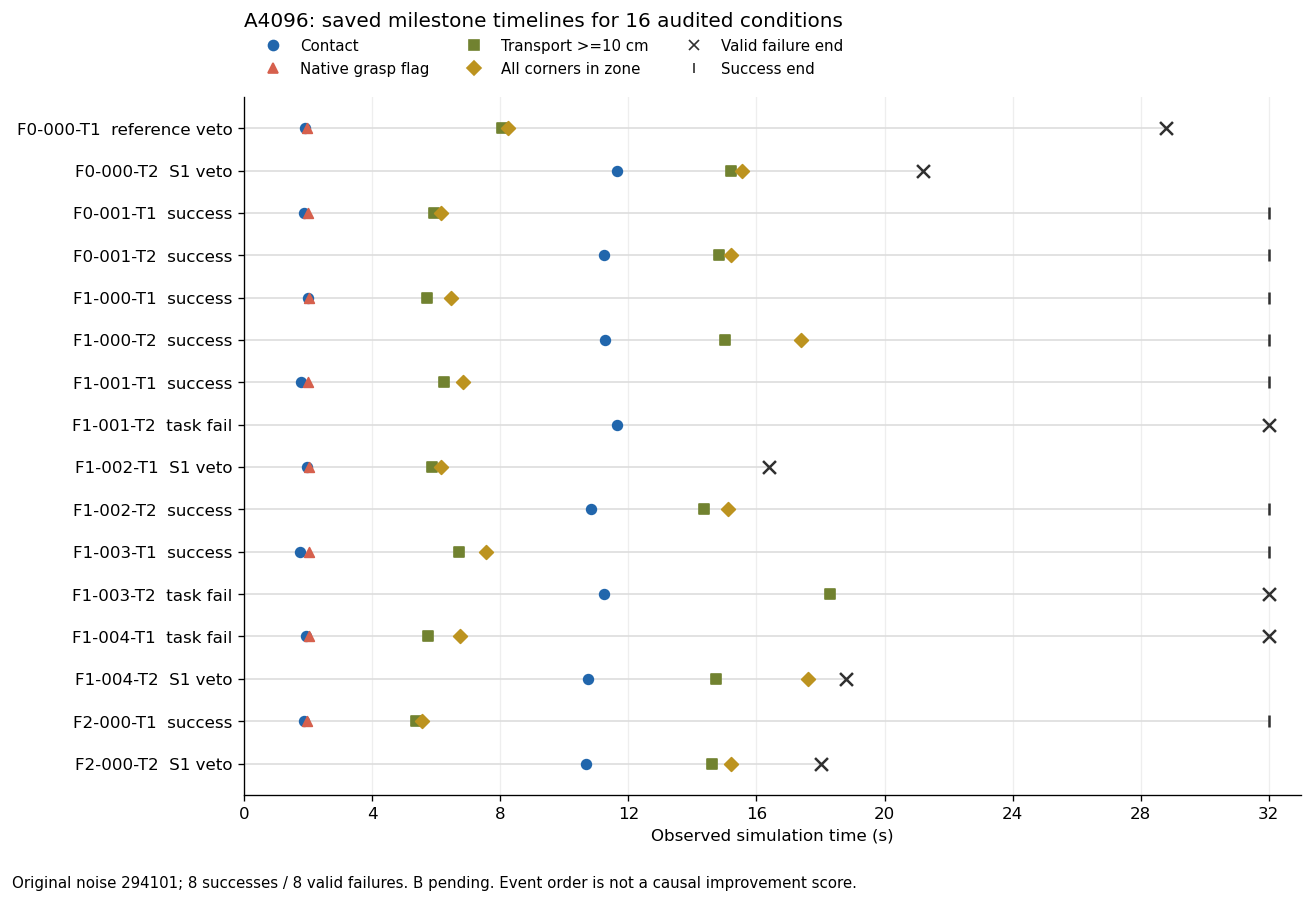

In [5]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'svg.fonttype':'none','svg.hashsalt':'V4A20261025'})
from IPython.display import Image
def show_figure(fig):
    preview=io.BytesIO();fig.savefig(preview,format='png',dpi=120,bbox_inches='tight');display(Image(data=preview.getvalue()))
FIGURES=REPORT_DIR/'figures'; FIGURES.mkdir(exist_ok=True)
rows=atlas['actual_condition_timelines'];fig,ax=plt.subplots(figsize=(11,7.6))
specs=[('actual_contact','Contact','#2166ac','o'),('native_grasp_flag','Native grasp flag','#d6604d','^'),('transport_at_least_10cm','Transport >=10 cm','#718230','s'),('all_corners_in_goal_zone','All corners in zone','#bc931f','D')]
for i,row in enumerate(rows):
    ax.hlines(i,0,row['actual_duration_s'],color='#dddddd',linewidth=1)
    for key,label,color,marker in specs:
        t=row['derived_event_timeline'][key]['first_s']
        if t is not None:ax.scatter(t,i,c=color,marker=marker,s=34,zorder=3,label=label if i==0 else None)
    ax.scatter(row['actual_duration_s'],i,c='#303030',marker='|' if row['status']=='SUCCESS' else 'x',s=60,zorder=4)
labels=[r['condition_id'].split('/DEV/')[1].replace('/N294101','').replace('/','-')+('  success' if r['status']=='SUCCESS' else '  '+{'ORIGINAL_REFERENCE_GATE_REJECT':'reference veto','S1_PRE_EXECUTION_REJECT':'S1 veto','OBJECT_TASK_RESULT':'task fail'}[r['failure_stage']]) for r in rows]
ax.set_yticks(range(len(rows)),labels);ax.invert_yaxis();ax.set_xlim(0,33);ax.set_xticks(np.arange(0,33,4));ax.set_xlabel('Observed simulation time (s)');ax.set_title('A4096: saved milestone timelines for 16 audited conditions',loc='left',pad=42)
# Use proxy marks so an absent first-row event never removes it from the legend.
from matplotlib.lines import Line2D
handles=[Line2D([],[],color=c,marker=m,linestyle='',label=l) for _,l,c,m in specs]+[Line2D([],[],color='#303030',marker='x',linestyle='',label='Valid failure end'),Line2D([],[],color='#303030',marker='|',linestyle='',label='Success end')]
ax.legend(handles=handles,ncol=3,loc='lower left',bbox_to_anchor=(0,1.01),frameon=False,fontsize=9)
ax.grid(axis='x',color='#eeeeee');fig.text(.01,.01,'Original noise 294101; 8 successes / 8 valid failures. B pending. Event order is not a causal improvement score.',fontsize=9);fig.tight_layout(rect=(0,.035,1,.99));fig.savefig(FIGURES/'V4A_A16_FAILURE_TIMELINES.svg',metadata={'Date':None},bbox_inches='tight');show_figure(fig);plt.close(fig)

Observed failures separate a reference-speed veto, S1 shadow pre-execution vetoes and full-duration object-task failures. Original vetoes never executed their rejected prefix in the live state. Partial episodes do not acquire padded object states, and a partial-score clock flag is not a failed raw-clock audit.

### Matched consumed-anchor composition

The total is fixed at 131,072 actual training visits per branch after the common initializer. This is exposure composition, not the number of independent scenes or a model-quality comparison.

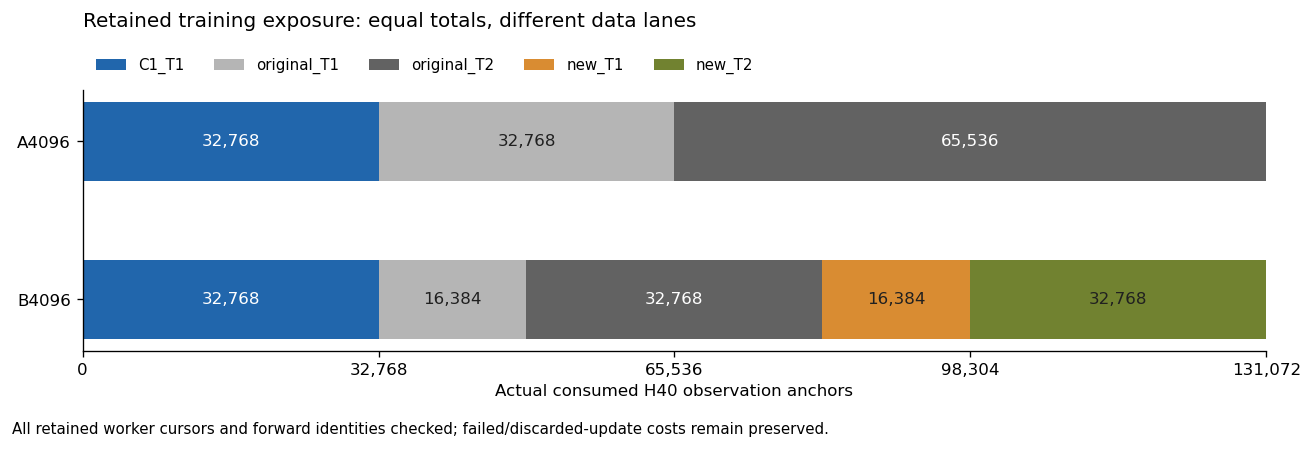

In [6]:
order=['C1_T1','original_T1','original_T2','new_T1','new_T2']
colors={'C1_T1':'#2166ac','original_T1':'#b5b5b5','original_T2':'#626262','new_T1':'#d98c32','new_T2':'#718230'}
fig,ax=plt.subplots(figsize=(11,3.7));left=np.zeros(2)
for lane in order:
    values=np.array([training['actual_by_candidate_lane'][a].get(lane,{}).get('actual_sample_visits',0) for a in ['A_CONTROL','B_COVERAGE']])
    ax.barh([0,1],values,left=left,color=colors[lane],label=lane,height=.5)
    for i,value in enumerate(values):
        if value:ax.text(left[i]+value/2,i,f'{value:,}',ha='center',va='center',color='white' if lane in ('C1_T1','original_T2') else '#202020')
    left+=values
assert np.all(left==131072)
ax.set_yticks([0,1],['A4096','B4096']);ax.invert_yaxis();ax.set_xlim(0,131072);ax.set_xticks([0,32768,65536,98304,131072]);ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'));ax.set_xlabel('Actual consumed H40 observation anchors');ax.set_title('Retained training exposure: equal totals, different data lanes',loc='left',pad=38);ax.legend(ncol=5,loc='lower left',bbox_to_anchor=(0,1.01),frameon=False,fontsize=9)
fig.text(.01,.01,'All retained worker cursors and forward identities checked; failed/discarded-update costs remain preserved.',fontsize=9);fig.tight_layout(rect=(0,.04,1,1));fig.savefig(FIGURES/'V4A_ACTUAL_TRAIN_LANE_MIX.svg',metadata={'Date':None},bbox_inches='tight');show_figure(fig);plt.close(fig)

### Event inclusion in consumed supervision

Teacher stages and physical transitions below have different definitions. Each fraction uses its own lane's actual sample count. Prefix8 inclusion means that an event or stage appears in the first eight supervised target points; it does not assert that a learned policy executed or mastered that event.

Label,Denominator,Prefix8,H40
A old T2: detach stage,65536,3416,6980
B old T2: detach stage,32768,1730,3482
B new T1: grasp end after transport,16384,159,1005
B new T2: zone entry,32768,441,2125


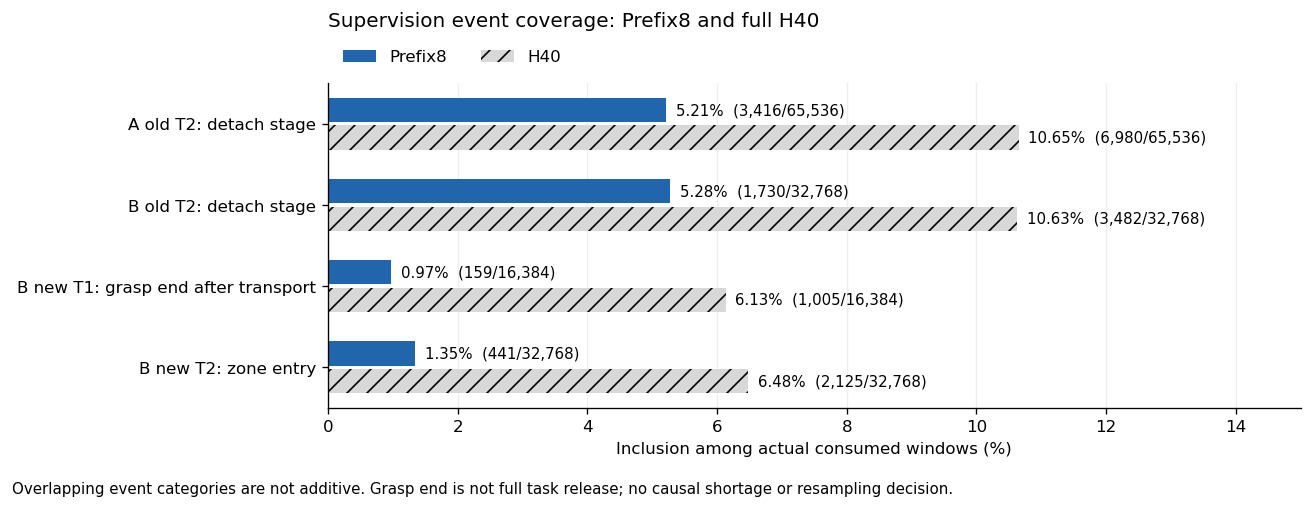

In [7]:
event_rows=[]
for arm in ['A_CONTROL','B_COVERAGE']:
    r=training['original_T2_Teacher_stage_supervision'][arm]['detach']
    event_rows.append({'Label':arm[0]+' old T2: detach stage','Denominator':r['actual_T2_samples'],'Prefix8':r['Prefix8_contains_stage'],'H40':r['H40_contains_stage']})
for lane,label in [('new_T1','B new T1: grasp end after transport'),('new_T2','B new T2: zone entry')]:
    r=training['B_new_bank_physical_event_supervision'][lane]
    event_rows.append({'Label':label,'Denominator':r['actual_sample_visits'],'Prefix8':r['Prefix8_actual_visit_hits'],'H40':r['H40_actual_visit_hits']})
table(event_rows)
fig,ax=plt.subplots(figsize=(11,4.2));y=np.arange(len(event_rows))
for offset,key,color,hatch in [(-.17,'Prefix8','#2166ac',None),(.17,'H40','#d8d8d8','//')]:
    values=[r[key]/r['Denominator']*100 for r in event_rows];ax.barh(y+offset,values,height=.30,color=color,hatch=hatch,label=key)
    for i,(value,row) in enumerate(zip(values,event_rows)):ax.text(value+.15,i+offset,f'{value:.2f}%  ({row[key]:,}/{row["Denominator"]:,})',va='center',fontsize=9)
ax.set_yticks(y,[r['Label'] for r in event_rows]);ax.invert_yaxis();ax.set_xlim(0,15);ax.set_xlabel('Inclusion among actual consumed windows (%)');ax.set_title('Supervision event coverage: Prefix8 and full H40',loc='left',pad=34);ax.legend(ncol=2,loc='lower left',bbox_to_anchor=(0,1.01),frameon=False);ax.grid(axis='x',color='#eeeeee');ax.set_axisbelow(True)
fig.text(.01,.01,'Overlapping event categories are not additive. Grasp end is not full task release; no causal shortage or resampling decision.',fontsize=9);fig.tight_layout(rect=(0,.04,1,1));fig.savefig(FIGURES/'V4A_ACTUAL_PREFIX8_EVENT_INCLUSION.svg',metadata={'Date':None},bbox_inches='tight');show_figure(fig);plt.close(fig)

### Future TRAIN-only candidate checks

Twelve pre-existing replicate-1 geometries span the 12 frozen appearance/direction/distance strata; each has T1 and T2. Historical static receipts remain distinct from current dynamic Teacher, codec and resource admission. No old closed request is reopened.

In [8]:
conditions=candidates['conditions'];assert len(conditions)==24
assert len({(r['scene_group'],r['task']) for r in conditions})==24
assert len({r['scene_group'] for r in conditions})==12 and all(r['split']=='TRAIN' and not r['new_execution'] for r in conditions)
assert not candidates['geometry_deduplication']['conflicts'] and candidates['dynamic_teacher_qualified'] is False
table([{'Appearance':r['appearance_profile'],'Direction':r['direction'],'Distance':r['distance_bin'],'Task':r['task'],'Replicate':r['replicate'],'Static receipt':r['existing_original_static_receipt_sha256'][:12]} for r in conditions[:8]])
print('24 metadata-only task conditions / 12 geometries; zero conflicts against 140 current geometry metadata records; dynamic Teacher and labels NOT_RUN.')

Appearance,Direction,Distance,Task,Replicate,Static receipt
AP0,+Y,NEAR,T1,1,b4cb8b96e7d7
AP0,+Y,NEAR,T2,1,125a3bd6f8df
AP0,+Y,FAR,T1,1,0d33f448e547
AP0,+Y,FAR,T2,1,08c8bbbf3e59
AP0,-Y,NEAR,T1,1,261b717a8f9d
AP0,-Y,NEAR,T2,1,de1d920e68da
AP0,-Y,FAR,T1,1,24e83ed01daf
AP0,-Y,FAR,T2,1,94d8d59f5f1c


24 metadata-only task conditions / 12 geometries; zero conflicts against 140 current geometry metadata records; dynamic Teacher and labels NOT_RUN.


## Takeaways

1. Preserve the server's existing A→B evaluation. The current Atlas supports diagnosis, not a B−A claim or formal model selection.
2. The actual retained training stream refutes “old T2 detach never appears” and quantifies a narrower Prefix8-versus-H40 distinction. Missing early-window inclusion is not missing full-H40 supervision or proof that extra sampling is needed.
3. C1 repetitions are intentional fixed-recipe exposure; eight exports do not create eight independent recoveries. No sampler or loss change follows automatically.
4. The 24 future conditions are a reusable design set only. New capture, new training, DAgger or target physics still require the original fresh qualification, valid scope and resources. DEV failures are not converted into TRAIN labels.
5. S1's fixed original CORR2048/R0 core64 remains incomplete. Existing target feedback/camera/STOP components are preserved; fullbody prefix execution qualification remains a separate gap.